# PLot results for paper

In [26]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [27]:
import glob
import pandas as pd
import os
import re


## Histogram of f1-score

In [28]:
# Adjust the path to where your folders are located
base_path=r"C:\Users\loren\Documents\Postdoc\Compressed_sensing\Data\Gibbon\results"
# Find all matching files in subdirectories
file_paths = glob.glob(f"{base_path}/*/*f1score_csv.csv")

In [29]:
# Extract and sort by numeric suffix
def sort_key(col, prefix):
    match = re.match(fr"{prefix}_(\d+)", col)
    return int(match.group(1)) if match else float('inf')

In [30]:
combined_df = pd.DataFrame()
clm=1 #column 0 : f1 score on the testing dataset , column 1 : f1 score on the entire dataset

for file_path in file_paths:

    filename = os.path.basename(file_path).replace(".csv", "")
    
    # Get the first word in the file name
    column_name = filename[7:-12]
    try:
        df = pd.read_csv(file_path)
        print(f"Loaded: {file_path}")
        first_column = df.iloc[:, clm] 
    except IndexError: 
        df = pd.read_csv(file_path, sep=";")
        print(f"Loaded: {file_path}")
        first_column = df.iloc[:, clm] #column 0 : f1 score on the testing dataset , column 1 : f1 score on the entire dataset

    combined_df[column_name] = first_column

Loaded: C:\Users\loren\Documents\Postdoc\Compressed_sensing\Data\Gibbon\results\gibbon_aac_40k\gibbon_aac_40k_f1score_csv.csv
Loaded: C:\Users\loren\Documents\Postdoc\Compressed_sensing\Data\Gibbon\results\gibbon_aac_8k\gibbon_aac_8k_f1score_csv.csv
Loaded: C:\Users\loren\Documents\Postdoc\Compressed_sensing\Data\Gibbon\results\gibbon_aac_96k\gibbon_aac_96k_f1score_csv.csv
Loaded: C:\Users\loren\Documents\Postdoc\Compressed_sensing\Data\Gibbon\results\gibbon_baseline\gibbon_None_None_f1score_csv.csv
Loaded: C:\Users\loren\Documents\Postdoc\Compressed_sensing\Data\Gibbon\results\gibbon_cs_0.1\gibbon_cs_0.1_f1score_csv.csv
Loaded: C:\Users\loren\Documents\Postdoc\Compressed_sensing\Data\Gibbon\results\gibbon_cs_0.2\gibbon_cs_0.2_f1score_csv.csv
Loaded: C:\Users\loren\Documents\Postdoc\Compressed_sensing\Data\Gibbon\results\gibbon_cs_0.3\gibbon_cs_0.3_f1score_csv.csv
Loaded: C:\Users\loren\Documents\Postdoc\Compressed_sensing\Data\Gibbon\results\gibbon_cs_0.3_npy\gibbon_cs_0.3_f1score_csv

In [31]:
# Rename the column
combined_df = combined_df.rename(columns={"None_None": "Baseline"})



# Separate and sort columns
baseline_col = ["Baseline"] if "Baseline" in combined_df.columns else []
aac_cols = sorted([col for col in combined_df.columns if col.startswith("aac_")], key=lambda x: sort_key(x, "aac"))
flac_cols = sorted([col for col in combined_df.columns if col.startswith("flac_")], key=lambda x: sort_key(x, "flac"))
mp3_cols = sorted([col for col in combined_df.columns if col.startswith("mp3_")], key=lambda x: sort_key(x, "mp3"))
opus_cols = sorted([col for col in combined_df.columns if col.startswith("opus_")], key=lambda x: sort_key(x, "opus"))
ogg_cols=sorted([col for col in combined_df.columns if col.startswith("ogg_")], key=lambda x: sort_key(x, "ogg"))
encodec_cols=sorted([col for col in combined_df.columns if col.startswith("encodec_")], key=lambda x: sort_key(x, "encodec"))
#cs_cols=sorted([col for col in combined_df.columns if col.startswith("cs_")], key=lambda x: sort_key(x, "cs"))

# Other columns
other_cols = [col for col in combined_df.columns if col not in (baseline_col + aac_cols +flac_cols + mp3_cols + opus_cols + ogg_cols + encodec_cols)]

# Reorder
new_order = baseline_col + aac_cols + flac_cols + mp3_cols + ogg_cols + opus_cols + encodec_cols + other_cols 
combined_df = combined_df[new_order]

# Show result
print(combined_df.columns)

Index(['Baseline', 'aac_8k', 'aac_40k', 'aac_96k', 'flac_0', 'flac_6',
       'flac_12', 'mp3_8k', 'mp3_32k', 'mp3_64k', 'ogg_0', 'ogg_5', 'ogg_10',
       'opus_8k', 'opus_40k', 'opus_112k', 'encodec_6.0', 'encodec_12.0',
       'encodec_24.0', 'cs_0.1', 'cs_0.2', 'cs_0.3', 'cs_0.4'],
      dtype='object')


In [32]:
print(combined_df.head())

   Baseline    aac_8k   aac_40k   aac_96k    flac_0    flac_6   flac_12  \
0  0.928219  0.846271  0.918535  0.928610  0.920904  0.921884  0.927938   
1  0.919275  0.822766  0.900922  0.931416  0.925177  0.895833  0.916711   
2  0.912360  0.888295  0.923767  0.923841  0.930901  0.932970  0.916486   
3  0.913430  0.845413  0.921634  0.908131  0.912201  0.882979  0.898674   
4  0.923660  0.855971  0.922049  0.926397  0.925028  0.933333  0.923752   

     mp3_8k   mp3_32k   mp3_64k  ...   opus_8k  opus_40k  opus_112k  \
0  0.908009  0.906410  0.925148  ...  0.882057  0.930383   0.924078   
1  0.908120  0.903654  0.909091  ...  0.898864  0.917031   0.924468   
2  0.911365  0.905345  0.919452  ...  0.907591  0.931806   0.935912   
3  0.921238  0.918345  0.914097  ...  0.891515  0.925148   0.923328   
4  0.914286  0.899889  0.925946  ...  0.896590  0.920354   0.921946   

   encodec_6.0  encodec_12.0  encodec_24.0    cs_0.1    cs_0.2    cs_0.3  \
0     0.903704      0.896885      0.910456  0.

C:\Users\loren\AppData\Local\Temp\ipykernel_9968\626675020.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(data=combined_df, color=".8", linewidth=.75, palette="Set1")


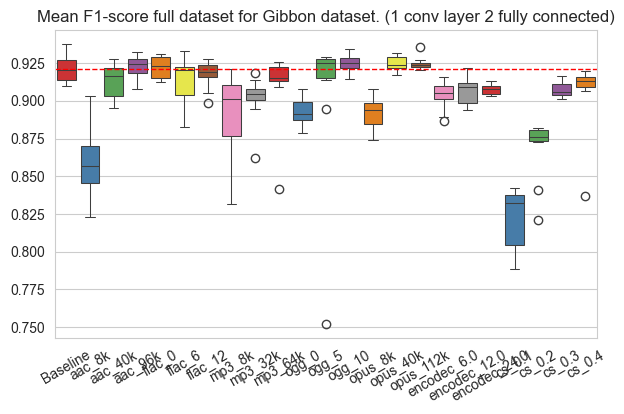

In [33]:
sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

ax = sns.boxplot(data=combined_df, color=".8", linewidth=.75, palette="Set1")
plt.axhline(y=np.mean(combined_df["Baseline"]), color='red', linestyle='--', linewidth=1, label=f'y = {np.mean(combined_df["Baseline"])}')
plt.title("Mean F1-score full dataset for Gibbon dataset. (1 conv layer 2 fully connected)")
plt.xticks(rotation=30)
plt.show()

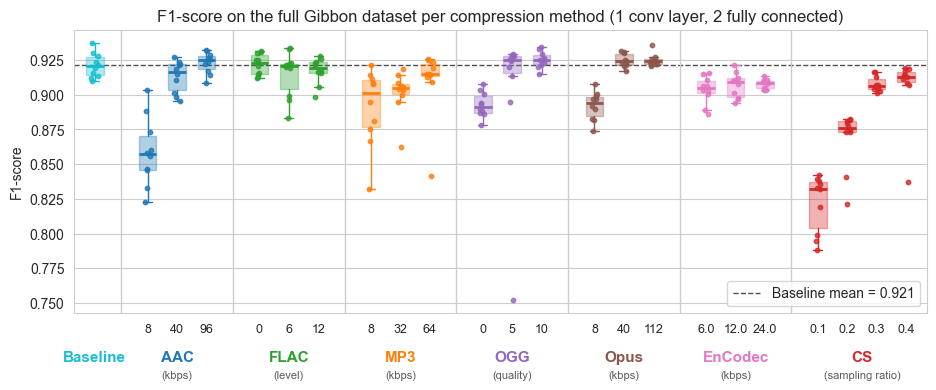

In [34]:
# Grouped boxplot: one colour per compression method, parameter under each box, method name under each group
# (label, column prefix, unit of the parameter, colour)
methods = [
    ("Baseline", "Baseline", "",               "#17becf"),
    ("AAC",      "aac",      "kbps",           "#1f77b4"),
    ("FLAC",     "flac",     "level",          "#2ca02c"),
    ("MP3",      "mp3",      "kbps",           "#ff7f0e"),
    ("OGG",      "ogg",      "quality",        "#9467bd"),
    ("Opus",     "opus",     "kbps",           "#8c564b"),
    ("EnCodec",  "encodec",  "kbps",           "#e377c2"),
    ("CS",       "cs",       "sampling ratio", "#d62728"),
]
gap = 0.8  # extra space between method groups

sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(11, 4.5))

pos = 0.0
tick_pos, tick_lab = [], []
for m_i, (label, prefix, unit, colour) in enumerate(methods):
    if prefix == "Baseline":
        cols = ["Baseline"] if "Baseline" in combined_df.columns else []
    else:
        cols = [c for c in combined_df.columns if c.startswith(prefix + "_")]
        cols = sorted(cols, key=lambda c: float(re.sub(r"[^\d.]", "", c.split("_", 1)[1])))
    if not cols:
        continue

    positions = [pos + i for i in range(len(cols))]
    data = [combined_df[c].dropna().values for c in cols]
    ax.boxplot(data, positions=positions, widths=0.6, patch_artist=True, showfliers=False,
               boxprops=dict(facecolor=colour, alpha=0.35, edgecolor=colour),
               medianprops=dict(color=colour, linewidth=2),
               whiskerprops=dict(color=colour), capprops=dict(color=colour))
    # individual runs
    for p, d in zip(positions, data):
        ax.scatter(p + np.random.uniform(-0.12, 0.12, len(d)), d, s=10, color=colour, alpha=0.8, zorder=3)

    tick_pos += positions
    tick_lab += ["" if prefix == "Baseline" else c.split("_", 1)[1].replace("k", "") for c in cols]

    # method name (and unit) centred below its group
    centre = np.mean(positions)
    ax.text(centre, -0.13, label, transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=11, fontweight="bold", color=colour)
    if unit:
        ax.text(centre, -0.20, f"({unit})", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=8, color="0.35")

    # separator before the next group
    if m_i < len(methods) - 1:
        ax.axvline(positions[-1] + (1 + gap) / 2, color="0.8", linewidth=1)
    pos = positions[-1] + 1 + gap

baseline_mean = combined_df["Baseline"].mean()
ax.axhline(baseline_mean, color="0.3", linestyle="--", linewidth=1,
           label=f"Baseline mean = {baseline_mean:.3f}", zorder=0)

ax.set_xticks(tick_pos, tick_lab, fontsize=9)
ax.set_xlim(-0.7, pos - gap - 0.3)
ax.set_ylabel("F1-score")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower right", frameon=True)
ax.set_title("F1-score on the full Gibbon dataset per compression method (1 conv layer, 2 fully connected)")
fig.subplots_adjust(bottom=0.25)
plt.show()

In [35]:
result_g=pd.read_csv(r"C:\Users\loren\Documents\Postdoc\Compressed_sensing\Data\Output\CS results - Gibbon.csv")

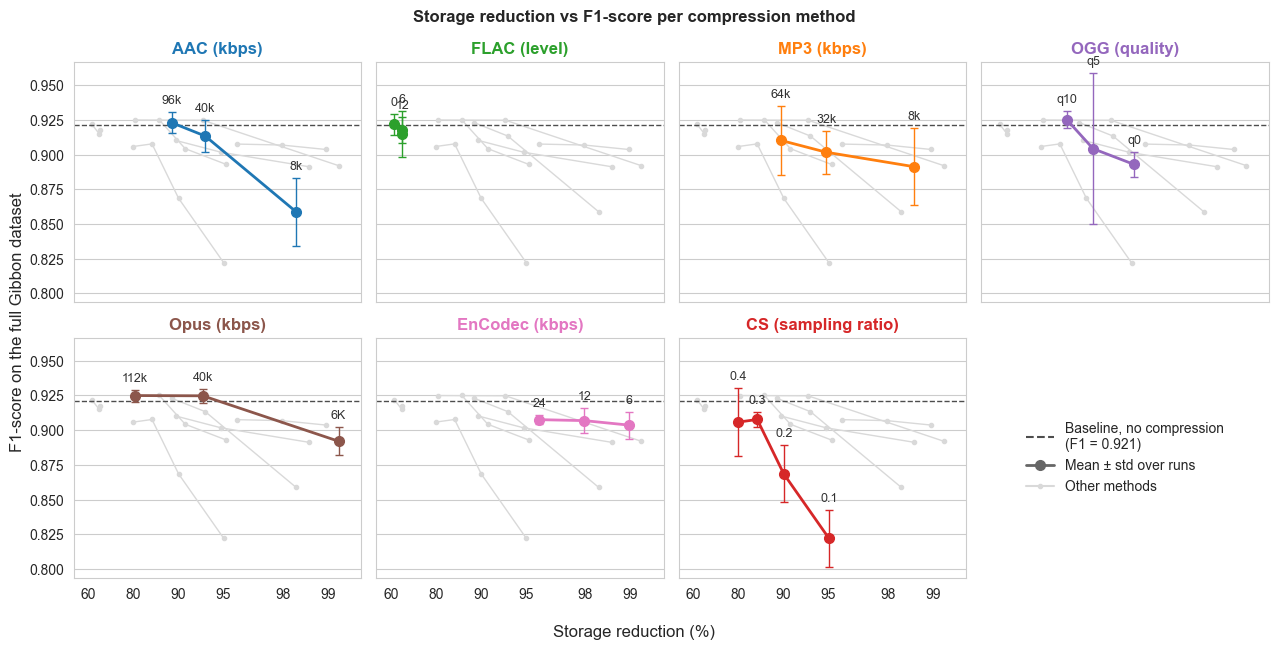

In [36]:
# Storage reduction (%) vs F1-score: mean +/- std over runs (from combined_df)
# One panel per method (other methods in light grey behind it for comparison)
# Uses `methods` (labels/colours) from the grouped boxplot cell above
from matplotlib.lines import Line2D

# result_g has two "storage reduction (%" columns: the first is computed from
# memory size, the second (".1") from the compression ratio -> use the first
storage_col = "storage reduction (%"

# result_g parameter that has a different name in the results folders
alias = {("opus", 6.0): ("opus", 8.0)}  # CSV says opus 6K, folder is opus_8k


def num(s):
    return float(re.sub(r"[^\d.]", "", str(s)))


# (method, numeric parameter) -> combined_df column, e.g. ("ogg", 5.0) -> "ogg_5"
f1_cols = {(c.split("_")[0], num(c.split("_", 1)[1])): c
           for c in combined_df.columns if c != "Baseline"}

rows = []
for _, r in result_g.iterrows():
    method = str(r["Compression method"]).strip().lower()
    if method == "baseline":
        continue
    key = (method, num(r["parameter"]))
    col = f1_cols.get(alias.get(key, key))
    if col is None:
        print("No F1 results found for", key)
        continue
    rows.append({"method": method,
                 "param": str(r["parameter"]).replace("-q", "q"),
                 "reduction": r[storage_col],
                 "f1_mean": combined_df[col].mean(),
                 "f1_std": combined_df[col].std()})
plot_df = pd.DataFrame(rows)
# Most points sit between 85 and 99 % reduction: plot the remaining size on a
# log axis (reversed) so they spread out, but label the ticks as reduction
plot_df["remaining"] = 100 - plot_df["reduction"]

panels = [m for m in methods if m[1] in set(plot_df["method"])]
baseline_mean = combined_df["Baseline"].mean()
reduction_ticks = [60, 80, 90, 95, 98, 99]

sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5), sharex=True, sharey=True)
axes = axes.ravel()

for ax, (label, prefix, unit, colour) in zip(axes, panels):
    # all other methods as grey context
    for other in plot_df["method"].unique():
        if other == prefix:
            continue
        o = plot_df[plot_df["method"] == other].sort_values("remaining")
        ax.plot(o["remaining"], o["f1_mean"], color="0.85", marker="o",
                markersize=3, linewidth=1, zorder=1)

    sub = plot_df[plot_df["method"] == prefix].sort_values("remaining")
    ax.errorbar(sub["remaining"], sub["f1_mean"], yerr=sub["f1_std"],
                color=colour, marker="o", markersize=7, linewidth=2,
                elinewidth=1, capsize=3, zorder=3)
    for _, r in sub.iterrows():
        ax.annotate(r["param"], (r["remaining"], r["f1_mean"] + r["f1_std"]),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, color="0.2")

    ax.axhline(baseline_mean, color="0.3", linestyle="--", linewidth=1,
               zorder=2)
    ax.set_title(f"{label} ({unit})" if unit else label,
                 color=colour, fontweight="bold")
    ax.set_xscale("log")
    ax.set_xlim(50, 0.6)  # reversed: more reduction to the right
    ax.set_xticks([100 - t for t in reduction_ticks],
                  [f"{t}" for t in reduction_ticks])
    ax.minorticks_off()
    ax.grid(axis="x", visible=False)

for ax in axes[len(panels):]:
    ax.axis("off")

# legend in the empty last panel
handles = [
    Line2D([], [], color="0.3", linestyle="--",
           label=f"Baseline, no compression\n(F1 = {baseline_mean:.3f})"),
    Line2D([], [], color="0.4", marker="o", markersize=7, linewidth=2,
           label="Mean ± std over runs"),
    Line2D([], [], color="0.85", marker="o", markersize=3,
           label="Other methods"),
]
axes[-1].legend(handles=handles, loc="center", frameon=False, fontsize=10)

fig.supxlabel("Storage reduction (%)")
fig.supylabel("F1-score on the full Gibbon dataset")
fig.suptitle("Storage reduction vs F1-score per compression method",
             fontweight="bold")
plt.tight_layout()
plt.show()

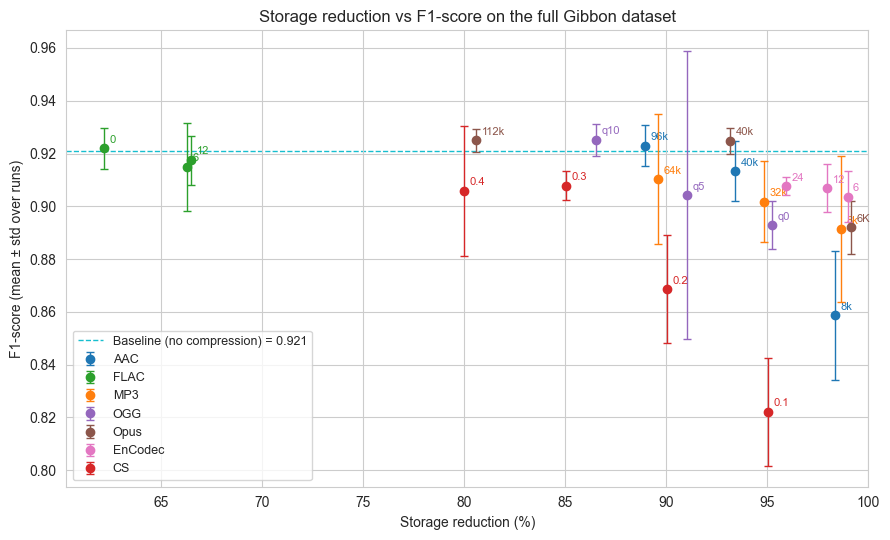

In [37]:
# Storage reduction (%) vs F1-score, all methods on one plot, points not joined
# Uses `plot_df` and `baseline_mean` from the panel cell above
sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(9, 5.5))

for label, prefix, unit, colour in methods:
    sub = plot_df[plot_df["method"] == prefix]
    if sub.empty:
        continue
    ax.errorbar(sub["reduction"], sub["f1_mean"], yerr=sub["f1_std"],
                color=colour, marker="o", markersize=6, linestyle="none",
                elinewidth=1, capsize=3, label=label, zorder=3)
    for _, r in sub.iterrows():
        ax.annotate(r["param"], (r["reduction"], r["f1_mean"]),
                    xytext=(4, 4), textcoords="offset points",
                    fontsize=8, color=colour)

ax.axhline(baseline_mean, color="#17becf", linestyle="--", linewidth=1,
           label=f"Baseline (no compression) = {baseline_mean:.3f}",
           zorder=0)

ax.set_xlabel("Storage reduction (%)")
ax.set_ylabel("F1-score (mean ± std over runs)")
ax.set_xlim(right=100)
ax.legend(loc="lower left", frameon=True, fontsize=9)
ax.set_title("Storage reduction vs F1-score on the full Gibbon dataset")
plt.tight_layout()
plt.show()

# Paper figures - all datasets

Settings, colours and paper style shared by every figure below. Figures are saved as PDF + PNG (300 dpi) in `Data/Output/figures`.

In [38]:
import os, re, glob
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

DATA_ROOT = r"C:\Users\loren\Documents\Postdoc\Compressed_sensing\Data"
FIG_DIR = os.environ.get("FIG_DIR", os.path.join(DATA_ROOT, "Output", "figures"))
os.makedirs(FIG_DIR, exist_ok=True)

# dataset label -> (folder in DATA_ROOT, summary csv in Data/Output or None)
DATASETS = {
    "Gibbon": ("Gibbon", "CS results - Gibbon.csv"),
    "Thyolo": ("Thyolo", "CS results - Thyolo.csv"),
    "PTW":    ("PTW",    "CS results - PTW.csv"),
    "Bats":   ("Bats",   None),
}

# Which F1 to use: "full" = entire dataset, "test" = test set
METRIC = "full"
# column names used for that score in the run files and in the summary tables
RUN_COLS = {"full": ["F1_score_full", "f1_score_full"],
            "test": ["F1_score", "f1_score_dataset"]}[METRIC]
CSV_METRIC = {"full": "f1-score entire files", "test": "f1-score"}[METRIC]

# Summary-table parameters named differently from the results folders
# (dataset, method, table value) -> folder value
ALIASES = {("Gibbon", "opus", 6.0): 8.0}  # table says opus 6K, folder is opus_8k

# key -> (label, colour, marker, True if a higher parameter = more compression)
METHODS = {
    "aac":     ("AAC",     "#1f77b4", "s", False),
    "mp3":     ("MP3",     "#ff7f0e", "^", False),
    "ogg":     ("OGG",     "#9467bd", "v", False),
    "opus":    ("Opus",    "#8c564b", "P", False),
    "flac":    ("FLAC",    "#2ca02c", "D", True),
    "encodec": ("EnCodec", "#e377c2", "X", False),
    "cs":      ("CS",      "#d62728", "o", False),
}

# Paper style: 8 pt text, figures sized for a 180 mm double column
mpl.rcParams.update({
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "0.9", "grid.linewidth": 0.6,
    "savefig.dpi": 300, "savefig.bbox": "tight", "pdf.fonttype": 42,
})
FULL_WIDTH = 7.1  # inches


def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"))


def num(s):
    s = re.sub(r"[^\d.]", "", str(s))
    return float(s) if s else np.nan

### Load the results

Run-level F1 from `<dataset>/results/*/*_f1score_csv.csv`; storage, time and mean F1 from `Data/Output/CS results - <dataset>.csv`. When a setting has no run files, the table's mean F1 is used (open marker, no error bar).

In [39]:
# Run-level F1 scores from <dataset>/results/<prefix>_<method>_<param>/*_f1score_csv.csv
def load_runs(name, folder):
    rows = []
    for path in glob.glob(os.path.join(DATA_ROOT, folder, "results", "*", "*_f1score_csv.csv")):
        setting = os.path.basename(os.path.dirname(path))
        if setting.lower().endswith("_baseline"):
            method, value = "baseline", np.nan
        else:
            m = re.search(r"_(aac|mp3|ogg|opus|flac|encodec|cs)_([\d.]+)k?$", setting, re.I)
            if m is None:
                print(f"[{name}] skipped folder {setting}")
                continue
            method, value = m.group(1).lower(), float(m.group(2))
        if not setting.lower().startswith(folder.lower()[:4]):
            print(f"[{name}] skipped folder from another dataset: {setting}")
            continue
        df = pd.read_csv(path)
        if df.shape[1] == 1 and ";" in df.columns[0]:
            df = pd.read_csv(path, sep=";")
        col = next((c for c in RUN_COLS if c in df.columns), df.columns[0])
        if col not in RUN_COLS:
            print(f"[{name}] {setting}: no {METRIC} F1 column, using {col}")
        for i, f1 in enumerate(df[col].dropna()):
            rows.append({"dataset": name, "method": method, "value": value,
                         "run": i, "f1": float(f1)})
    return pd.DataFrame(rows)


# Summary table: storage, time and mean F1 per setting
def load_summary(name, csv):
    if csv is None:
        return pd.DataFrame()
    df = pd.read_csv(os.path.join(DATA_ROOT, "Output", csv))
    first_empty = df.index[df.isna().all(axis=1)]
    if len(first_empty):  # notes below the table (e.g. other datasets)
        df = df.loc[:first_empty[0] - 1]
    df["method"] = df["Compression method"].str.strip().str.lower()
    df["value"] = df["parameter"].map(num)
    df["value"] = [ALIASES.get((name, m, v), v) for m, v in zip(df["method"], df["value"])]
    base_size = df.loc[df["method"] == "baseline", "memory size (GB)"].iloc[0]
    out = pd.DataFrame({
        "dataset": name, "method": df["method"], "value": df["value"],
        "param": df["parameter"].fillna("").astype(str).str.replace("-q", "q").str.replace("K", "k"),
        # storage reduction recomputed from the file sizes so all datasets match
        "reduction": 100 * (1 - df["memory size (GB)"] / base_size),
        "csv_f1": pd.to_numeric(df[CSV_METRIC], errors="coerce") / 100,
        "encode_s": pd.to_numeric(df.get("time (sec)"), errors="coerce"),
        "reconstruct_s": pd.to_numeric(df.get("reconstruction (sec)"), errors="coerce"),
        "raw_gb": base_size,
    })
    return out


runs = pd.concat([load_runs(n, f) for n, (f, c) in DATASETS.items()], ignore_index=True)
csvs = pd.concat([load_summary(n, c) for n, (f, c) in DATASETS.items()], ignore_index=True)

# One row per (dataset, setting): F1 from the runs if we have them, else the
# summary-table value (no error bar, drawn as an open marker)
stats = (runs.groupby(["dataset", "method", "value"], dropna=False)["f1"]
         .agg(f1_mean="mean", f1_std="std", n_runs="count").reset_index())
summary = csvs.merge(stats, on=["dataset", "method", "value"], how="outer")
summary["from_runs"] = summary["n_runs"].fillna(0) > 0
summary["f1"] = summary["f1_mean"].where(summary["from_runs"], summary["csv_f1"])
summary["param"] = summary["param"].fillna(summary["value"].map(lambda v: f"{v:g}"))

baseline = summary[summary["method"] == "baseline"].set_index("dataset")
summary["base_f1"] = summary["dataset"].map(baseline["f1"])
summary["base_std"] = summary["dataset"].map(baseline["f1_std"])
summary["delta"] = 100 * (summary["f1"] - summary["base_f1"])  # percentage points
summary["delta_std"] = 100 * summary["f1_std"]
summary = summary[summary["method"] != "baseline"].dropna(subset=["f1"])

# Rank settings within a method: 1 = least compression
summary["level"] = 0
for (ds, m), g in summary.groupby(["dataset", "method"]):
    summary.loc[g.index, "level"] = g["value"].rank(
        ascending=METHODS[m][3], method="dense").astype(int)
DATASET_ORDER = [d for d in DATASETS if d in set(summary["dataset"])]

[Gibbon] skipped folder gibbon_cs_0.3_npy
[Bats] bats_baseline: no full F1 column, using F1_score
[Bats] bats_cs_0.1: no full F1 column, using F1_score
[Bats] bats_cs_0.2: no full F1 column, using F1_score


### Data availability check

In [40]:
avail = summary.assign(src=np.where(summary["from_runs"],
                                    summary["n_runs"].fillna(0).astype(int).astype(str) + " runs",
                                    "table only"))
print(f"Baseline F1 ({METRIC}):")
print((100 * baseline[["f1", "f1_std"]]).round(2))
print("\nWhere each F1 value comes from:")
print(avail.pivot_table(index=["method", "param"], columns="dataset", values="src",
                        aggfunc="first").reindex(columns=DATASET_ORDER).fillna("-"))

Baseline F1 (full):
            f1  f1_std
dataset               
Bats     85.77    1.84
Gibbon   92.11    0.88
PTW      71.03     NaN
Thyolo   71.06    1.54

Where each F1 value comes from:
dataset         Gibbon   Thyolo         PTW     Bats
method  param                                       
aac     144k         -        -  table only        -
        40k    10 runs  10 runs           -        -
        56k          -        -  table only        -
        8k     10 runs  10 runs  table only        -
        96k    10 runs  10 runs           -        -
cs      0.1    10 runs  10 runs     10 runs  10 runs
        0.2    10 runs  10 runs     10 runs  10 runs
        0.3    10 runs  10 runs     10 runs        -
        0.4    10 runs        -           -        -
encodec 12     10 runs  10 runs     10 runs        -
        24     10 runs  10 runs  table only        -
        6      10 runs  10 runs  table only        -
flac    0      10 runs  10 runs  table only        -
        12    

### Figure 1 - Change in F1 vs storage reduction

ΔF1 relative to the uncompressed baseline (percentage points), mean ± std over runs. Grey band = baseline run-to-run spread. Points below the floor are drawn as ▼ with their value.

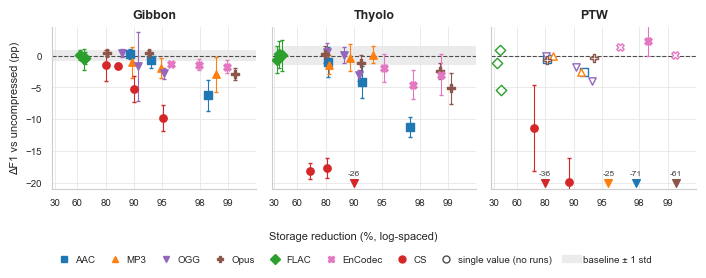

In [41]:
# Figure 1 - change in F1 vs storage reduction, one panel per dataset
Y_FLOOR = -20  # pp; points below are drawn on the floor with their value
red_ticks = [30, 60, 80, 90, 95, 98, 99]
plot_sets = [d for d in DATASET_ORDER if summary.loc[summary.dataset == d, "reduction"].notna().any()]

fig, axes = plt.subplots(1, len(plot_sets), figsize=(FULL_WIDTH, 2.6), sharey=True)
axes = np.atleast_1d(axes)
for ax, ds in zip(axes, plot_sets):
    d = summary[(summary.dataset == ds) & summary.reduction.notna()]
    rem = 100 - d["reduction"]

    # baseline run-to-run spread (+/- 1 std) as a grey band around 0
    bs = 100 * baseline.loc[ds, "f1_std"]
    if pd.notna(bs):
        ax.axhspan(-bs, bs, color="0.92", zorder=0, lw=0)
    ax.axhline(0, color="0.3", lw=0.8, ls="--", zorder=1)

    for key, (label, colour, marker, _) in METHODS.items():
        s = d[d.method == key]
        for _, r in s.iterrows():
            x, y = 100 - r.reduction, r.delta
            filled = r.from_runs
            if y < Y_FLOOR:
                ax.scatter(x, Y_FLOOR, marker="v", s=30, color=colour, zorder=4, clip_on=False)
                ax.annotate(f"{y:.0f}", (x, Y_FLOOR), xytext=(0, 5), textcoords="offset points",
                            ha="center", fontsize=6, color="0.25")
                continue
            if filled and pd.notna(r.delta_std):
                ax.errorbar(x, y, yerr=r.delta_std, color=colour, lw=0.8, capsize=1.5, zorder=2)
            ax.scatter(x, y, marker=marker, s=28, zorder=3,
                       facecolor=colour if filled else "white", edgecolor=colour, linewidth=1)

    ax.set_xscale("log")
    ax.set_xlim(75, 0.5)
    ax.set_xticks([100 - t for t in red_ticks], [str(t) for t in red_ticks])
    ax.minorticks_off()
    ax.set_ylim(Y_FLOOR - 1, None)
    ax.set_title(ds, fontweight="bold")
axes[0].set_ylabel(f"ΔF1 vs uncompressed (pp)")
fig.supxlabel("Storage reduction (%, log-spaced)", fontsize=8, y=0.06)

handles = [Line2D([], [], ls="none", marker=m, color=c, markersize=5, label=l)
           for l, c, m, _ in METHODS.values()]
handles += [Line2D([], [], ls="none", marker="o", mfc="white", mec="0.3", markersize=5,
                   label="single value (no runs)"),
            mpl.patches.Patch(color="0.92", label="baseline ± 1 std")]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False,
           bbox_to_anchor=(0.5, -0.06), handletextpad=0.2, columnspacing=1.0)
fig.tight_layout(rect=(0, 0.06, 1, 1))
save(fig, "fig1_delta_f1_vs_storage")
plt.show()

### Figure 2 - Overview heatmap

ΔF1 for every method, setting and dataset (setting and value in each cell).

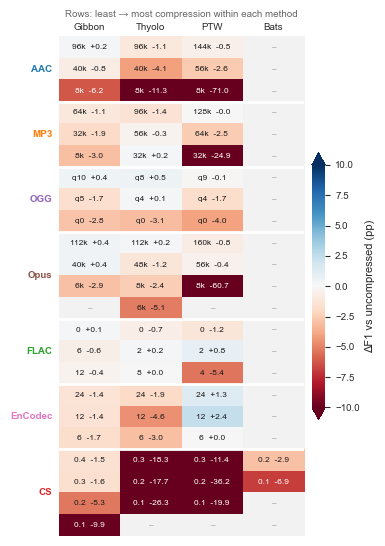

In [42]:
# Figure 2 - heatmap of the change in F1 for every method, setting and dataset
LIM = 10  # colour scale saturates at +/- LIM pp
max_level = summary.groupby("method")["level"].max()
row_keys = [(m, l) for m in METHODS for l in range(1, int(max_level.get(m, 0)) + 1)]

delta = summary.pivot_table(index=["method", "level"], columns="dataset", values="delta",
                            aggfunc="first").reindex(index=row_keys, columns=DATASET_ORDER)
labels = summary.pivot_table(index=["method", "level"], columns="dataset", values="param",
                             aggfunc="first").reindex(index=row_keys, columns=DATASET_ORDER)

cmap = mpl.colormaps["RdBu"].copy()
cmap.set_bad("0.95")
fig, ax = plt.subplots(figsize=(3.9, 0.2 * len(row_keys) + 0.9))
im = ax.imshow(np.clip(delta.values, -LIM, LIM), cmap=cmap, vmin=-LIM, vmax=LIM, aspect="auto")

for i in range(delta.shape[0]):
    for j in range(delta.shape[1]):
        v = delta.iat[i, j]
        if pd.isna(v):
            ax.text(j, i, "–", ha="center", va="center", fontsize=6, color="0.6")
            continue
        txt = f"{labels.iat[i, j]}  {v:+.1f}"
        ax.text(j, i, txt, ha="center", va="center", fontsize=6,
                color="white" if abs(v) > 0.6 * LIM else "0.1")

# method name once per block, separator lines between methods
ax.set_yticks(range(len(row_keys)), [""] * len(row_keys))
start = 0
for m in METHODS:
    n = int(max_level.get(m, 0))
    if n == 0:
        continue
    ax.text(-0.6, start + (n - 1) / 2, METHODS[m][0], ha="right", va="center",
            fontsize=7, fontweight="bold", color=METHODS[m][1])
    if start > 0:
        ax.axhline(start - 0.5, color="white", lw=2)
    start += n
ax.tick_params(axis="y", length=0)
ax.set_xticks(range(len(DATASET_ORDER)), DATASET_ORDER)
ax.xaxis.tick_top()
ax.tick_params(axis="x", length=0)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03, extend="both")
cb.set_label("ΔF1 vs uncompressed (pp)")
cb.outline.set_visible(False)
ax.set_title("Rows: least → most compression within each method", fontsize=7,
             color="0.4", pad=14)
fig.tight_layout()
save(fig, "fig2_delta_f1_heatmap")
plt.show()

### Figure 3 - Run-to-run distribution of F1 per dataset

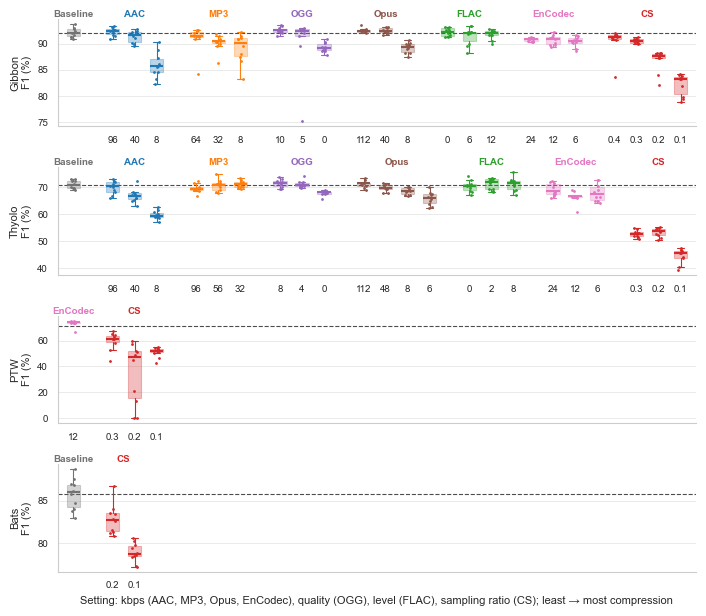

In [43]:
# Figure 3 - run-to-run distribution of F1 per setting, one row per dataset
box_sets = [d for d in DATASET_ORDER if (runs.dataset == d).any()]
fig, axes = plt.subplots(len(box_sets), 1, figsize=(FULL_WIDTH, 1.55 * len(box_sets)),
                         sharex=False)
axes = np.atleast_1d(axes)
gap = 0.8
x_max = 0
for ax, ds in zip(axes, box_sets):
    r = runs[runs.dataset == ds]
    pos, ticks, ticklab = 0.0, [], []
    groups = [("baseline", "Baseline", "0.45")] + [(k, v[0], v[1]) for k, v in METHODS.items()]
    for key, label, colour in groups:
        s = r[r.method == key]
        if s.empty:
            continue
        vals = sorted(s["value"].dropna().unique(), reverse=not (key == "flac")) if key != "baseline" else [np.nan]
        data = [100 * (s["f1"] if key == "baseline" else s.loc[s.value == v, "f1"]).values for v in vals]
        p = [pos + i for i in range(len(vals))]
        ax.boxplot(data, positions=p, widths=0.6, patch_artist=True, showfliers=False,
                   boxprops=dict(facecolor=colour, alpha=0.3, edgecolor=colour, lw=0.8),
                   medianprops=dict(color=colour, lw=1.5),
                   whiskerprops=dict(color=colour, lw=0.8), capprops=dict(color=colour, lw=0.8))
        rng = np.random.default_rng(0)
        for x, y in zip(p, data):
            ax.scatter(x + rng.uniform(-0.12, 0.12, len(y)), y, s=4, color=colour, zorder=3, lw=0)
        ticks += p
        ticklab += ["" if key == "baseline" else f"{v:g}" for v in vals]
        ax.text(np.mean(p), 1.0, label, transform=ax.get_xaxis_transform(), ha="center",
                va="bottom", fontsize=7, fontweight="bold", color=colour)
        pos = p[-1] + 1 + gap
    ax.axhline(100 * baseline.loc[ds, "f1"], color="0.3", lw=0.8, ls="--", zorder=0)
    ax.set_xticks(ticks, ticklab)
    x_max = max(x_max, pos - gap - 0.3)
    ax.grid(axis="x", visible=False)
    ax.set_ylabel(f"{ds}\nF1 (%)")
for ax in axes:  # same x scale on every row so boxes have the same width
    ax.set_xlim(-0.7, x_max)
axes[-1].set_xlabel("Setting: kbps (AAC, MP3, Opus, EnCodec), quality (OGG), level (FLAC), "
                    "sampling ratio (CS); least → most compression")
fig.tight_layout(h_pad=1.2)
save(fig, "fig3_f1_distribution_per_dataset")
plt.show()

### Figure 4 - Processing cost

Compression and decoding/reconstruction time normalised by the raw dataset size.

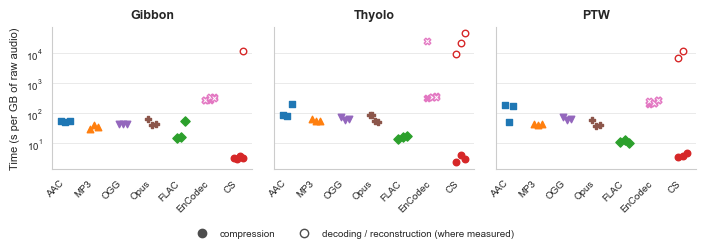

In [44]:
# Figure 4 - processing cost: encoding and decoding/reconstruction time per GB of raw audio
cost = summary[summary.encode_s.notna() | summary.reconstruct_s.notna()].copy()
cost["enc"] = cost.encode_s / cost.raw_gb
cost["rec"] = cost.reconstruct_s / cost.raw_gb
cost_sets = [d for d in DATASET_ORDER if (cost.dataset == d).any()]

fig, axes = plt.subplots(1, len(cost_sets), figsize=(FULL_WIDTH, 2.4), sharey=True)
axes = np.atleast_1d(axes)
keys = list(METHODS)
for ax, ds in zip(axes, cost_sets):
    c = cost[cost.dataset == ds]
    for i, key in enumerate(keys):
        label, colour, marker, _ = METHODS[key]
        s = c[c.method == key]
        jit = np.linspace(-0.15, 0.15, len(s)) if len(s) > 1 else [0]
        ax.scatter(i + np.asarray(jit), s.enc, marker=marker, s=22, color=colour, zorder=3)
        rec = s.rec.where(s.rec > 0)
        ax.scatter(i + np.asarray(jit), rec, marker=marker, s=22, facecolor="white",
                   edgecolor=colour, lw=1, zorder=3)
    ax.set_yscale("log")
    ax.set_xticks(range(len(keys)), [METHODS[k][0] for k in keys], rotation=45, ha="right")
    ax.grid(axis="x", visible=False)
    ax.set_title(ds, fontweight="bold")
axes[0].set_ylabel("Time (s per GB of raw audio)")
fig.legend(handles=[Line2D([], [], ls="none", marker="o", color="0.3", label="compression"),
                    Line2D([], [], ls="none", marker="o", mfc="white", mec="0.3",
                           label="decoding / reconstruction (where measured)")],
           loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.05, 1, 1))
save(fig, "fig4_processing_time")
plt.show()